# Analiza calității și a prețurilor unui catalog fictiv de produse

## Obiectiv
Analizez calitatea datelor dintr-un catalog simulat și explorez modul în care prețurile diferă între categoriile de produse.

## Întrebări
1. Cât de complete și de consecvente sunt înregistrările?
2. Cum sunt distribuite prețurile în catalog și între categorii?
3. Ce înregistrări ar trebui verificate înainte ca acest catalog să fie folosit?

## Limitări
Datele sunt fictive și nu includ vânzări, stocuri sau informații despre clienți. Prin urmare, analiza poate descrie catalogul, dar nu poate măsura cererea sau performanța comercială reală.


In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

print("Versiunea pandas:", pd.__version__)

Versiunea pandas: 3.0.3


In [1]:
from pathlib import Path

file_path = Path("catalog_1000_produse_simulat.xlsx")

print("Fișierul a fost găsit:", file_path.exists())

Fișierul a fost găsit: True


In [4]:
excel_file = pd.ExcelFile(file_path)
print(excel_file.sheet_names)

['Catalog produse', 'Dicționar date']


In [5]:
df = pd.read_excel(file_path, sheet_name="Catalog produse")
data_dictionary = pd.read_excel(file_path, sheet_name="Dicționar date")

print("Dimensiunea catalogului:", df.shape)
display(df.head())
display(data_dictionary)

Dimensiunea catalogului: (1000, 12)


,ID produs,Denumire produs,Brand,Categorie,Model,Specificații tehnice,Descriere scurtă,Preț (lei),Monedă,Cod EAN (simulat),Status date,Problemă identificată
0,PRD-00001,Smartphone Samsung Nova-859,Samsung,Smartphone,Nova-859,128 GB; 4 GB RAM; Ecran 6.4 inch,"Smartphone Samsung Nova-859, cu 128 gb; 4 gb r...",5199,RON,2000000000015,Complet,Nicio eroare identificată
1,PRD-00002,Smartphone Samsung Ultra-189,Samsung,Smartphone,Ultra-189,128 GB; 4 GB RAM; Ecran 6.4 inch,"Smartphone Samsung Ultra-189, cu 128 gb; 4 gb ...",1849,RON,2000000000022,Complet,Nicio eroare identificată
2,PRD-00003,Telefon mobil Xiaomi Ultra-716,Xiaomi,Smartphone,Ultra-716,512 GB; 6 GB RAM; Ecran 6.7 inch,"Telefon mobil Xiaomi Ultra-716, cu 512 gb; 6 g...",4649,RON,2000000000039,Complet,Nicio eroare identificată
3,PRD-00004,Smartphone OnePlus Essential-325,OnePlus,Smartphone,Essential-325,256 GB; 4 GB RAM; Ecran 6.4 inch,"Smartphone OnePlus Essential-325, cu 256 gb; 4...",4949,RON,2000000000046,Complet,Nicio eroare identificată
4,PRD-00005,Telefon mobil Nokia Smart-384,Nokia,Smartphone,Smart-384,128 GB; 8 GB RAM; Ecran 6.1 inch,"Telefon mobil Nokia Smart-384, cu 128 gb; 8 gb...",1049,RON,2000000000053,Complet,Nicio eroare identificată


,Câmp,Explicație
0,ID produs,Identificator intern unic al înregistrării.
1,Denumire produs,Denumire comercială simulată.
2,Brand,Marcă folosită în exemplul de catalog.
3,Categorie,Categoria principală a produsului.
4,Model,Cod de model fictiv.
5,Specificații tehnice,"Specificații exemplificative, generate pentru ..."
6,Descriere scurtă,Descriere generată automat din denumire și spe...
7,Preț (lei),"Preț fictiv, în RON."
8,Cod EAN (simulat),"Cod numeric de test, cu cifră de control EAN-1..."
9,Status date,Indicator simulat pentru exerciții de control ...


In [6]:
df.info()

print("\nValori lipsă pe coloană:")
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   ID produs              1000 non-null   str  
 1   Denumire produs        1000 non-null   str  
 2   Brand                  1000 non-null   str  
 3   Categorie              1000 non-null   str  
 4   Model                  1000 non-null   str  
 5   Specificații tehnice   1000 non-null   str  
 6   Descriere scurtă       1000 non-null   str  
 7   Preț (lei)             1000 non-null   int64
 8   Monedă                 1000 non-null   str  
 9   Cod EAN (simulat)      1000 non-null   int64
 10  Status date            1000 non-null   str  
 11  Problemă identificată  1000 non-null   str  
dtypes: int64(2), str(10)
memory usage: 293.1 KB

Valori lipsă pe coloană:
ID produs                0
Denumire produs          0
Brand                    0
Categorie                0
Model                 

In [7]:
print("ID-uri de produs duplicate:", df["ID produs"].duplicated().sum())
print("Coduri EAN duplicate:", df["Cod EAN (simulat)"].duplicated().sum())

print("\nStatusul înregistrărilor:")
display(df["Status date"].value_counts().to_frame("Număr"))

print("\nProblemele marcate:")
display(df["Problemă identificată"].value_counts().to_frame("Număr"))

ID-uri de produs duplicate: 0
Coduri EAN duplicate: 0

Statusul înregistrărilor:


,Număr
Status date,
Complet,941
Necesită verificare,59



Problemele marcate:


,Număr
Problemă identificată,
Nicio eroare identificată,941
Descriere incompletă,27
Specificație posibil contradictorie,18
Brand/model de verificat,14


In [8]:
flagged = df[df["Status date"] == "Necesită verificare"]
issue_counts = flagged["Problemă identificată"].value_counts()

issue_summary = pd.DataFrame({
    "Număr": issue_counts,
    "% din catalog": (issue_counts / len(df) * 100).round(1),
    "% din cele semnalate": (issue_counts / len(flagged) * 100).round(1)
})

display(issue_summary)

,Număr,% din catalog,% din cele semnalate
Problemă identificată,,,
Descriere incompletă,27,2.7,45.8
Specificație posibil contradictorie,18,1.8,30.5
Brand/model de verificat,14,1.4,23.7


## Calitatea datelor

Toate cele 1.000 de produse au valori completate, iar ID-urile de produs și codurile EAN nu se repetă. Totuși, 59 de înregistrări (5,9%) sunt marcate pentru verificare. Cea mai frecventă problemă este descrierea incompletă, prezentă la 27 de produse, adică 45,8% dintre înregistrările semnalate. Urmează specificațiile posibil contradictorii (18 produse) și brandul sau modelul de verificat (14 produse). Aceste marcaje sunt furnizate în catalogul simulat și nu au fost verificate independent.

In [9]:
price_summary = df["Preț (lei)"].describe()
display(price_summary.to_frame("Valoare").round(2))

,Valoare
count,1000.00
mean,2358.45
std,2351.47
min,9.00
25%,549.00
50%,1454.00
75%,3399.00
max,9999.00


In [10]:
price_by_category = (
    df.groupby("Categorie")["Preț (lei)"]
      .agg(["count", "mean", "median", "min", "max"])
      .sort_values("median", ascending=False)
      .round(2)
)

display(price_by_category)

,count,mean,median,min,max
Categorie,,,,,
Laptop,100,6303.00,6349.0,1799,9999
Televizor,100,4745.00,4849.0,699,8899
Smartphone,100,3325.50,3324.0,549,6499
Electrocasnice mari,100,3470.00,3199.0,699,6499
Gaming,100,1857.50,1824.0,99,3399
Unelte,100,1440.25,1574.0,99,2499
Electrocasnice mici,100,789.60,839.0,89,1469
Audio,100,875.10,794.0,109,1769
Periferice PC,100,503.10,544.0,29,889


## Prețuri pe categorii

Prețul median este cel mai ridicat la categoria Laptop (6.349 lei), urmată de Televizor (4.849 lei). Categoria Iluminat are cea mai mică mediană (306,5 lei). Toate categoriile conțin câte 100 de produse, însă prețurile sunt fictive; aceste rezultate descriu structura catalogului simulat și nu trebuie interpretate ca estimări ale pieței.

df.boxplot(
    column="Preț (lei)",
    by="Categorie",
    vert=False,
    figsize=(10, 6),
    grid=False
)

plt.suptitle("")
plt.title("Distribuția prețurilor pe categorii")
plt.xlabel("Preț (lei)")
plt.ylabel("Categorie")
plt.tight_layout()
plt.show()

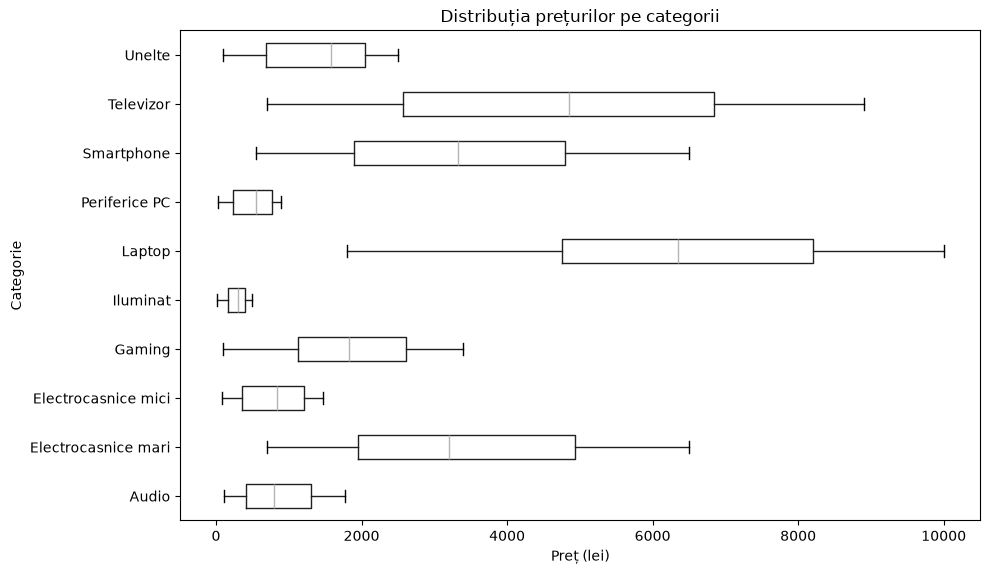

In [13]:
df.boxplot(
    column="Preț (lei)",
    by="Categorie",
    vert=False,
    figsize=(10, 6),
    grid=False
)

plt.suptitle("")
plt.title("Distribuția prețurilor pe categorii")
plt.xlabel("Preț (lei)")
plt.ylabel("Categorie")
plt.tight_layout()
plt.show()

În boxplot, categoria Televizor are cea mai mare răspândire a prețurilor în intervalul central al distribuției. Aceasta indică o variație mai mare a prețurilor din catalog pentru televizoare, nu o diferență de vânzări sau cerere.

In [14]:
def ean13_valid(value):
    code = str(value).strip()

    if len(code) != 13 or not code.isdigit():
        return False

    digits = [int(digit) for digit in code]
    weighted_sum = sum(digits[0:12:2]) + 3 * sum(digits[1:12:2])
    check_digit = (10 - weighted_sum % 10) % 10

    return check_digit == digits[12]


ean_valid = df["Cod EAN (simulat)"].map(ean13_valid)

print("Coduri EAN cu format/cifră de control invalidă:", (~ean_valid).sum())
print("Prețuri zero sau negative:", (df["Preț (lei)"] <= 0).sum())
print("\nMonede în catalog:")
display(df["Monedă"].value_counts())

Coduri EAN cu format/cifră de control invalidă: 0
Prețuri zero sau negative: 0

Monede în catalog:


Monedă
RON    1000
Name: count, dtype: int64

### Validări suplimentare

Toate codurile EAN simulate trec verificarea formatului și a cifrei de control. Nu există prețuri zero sau negative, iar toate cele 1.000 de produse sunt în RON. Validarea cifrei de control nu confirmă că EAN-urile simulate au fost alocate oficial. Codul EAN este un identificator și ar trebui tratat ca text în analizele următoare.

In [15]:
df_clean = df.copy()
df_clean["Cod EAN (simulat)"] = df_clean["Cod EAN (simulat)"].astype("string")

print("Tipul coloanei EAN:", df_clean["Cod EAN (simulat)"].dtype)

Tipul coloanei EAN: string


In [16]:
prices_by_category = df_clean.groupby("Categorie")["Preț (lei)"]

q1 = prices_by_category.transform(lambda prices: prices.quantile(0.25))
q3 = prices_by_category.transform(lambda prices: prices.quantile(0.75))
iqr = q3 - q1

outlier_mask = (
    (df_clean["Preț (lei)"] < q1 - 1.5 * iqr)
    | (df_clean["Preț (lei)"] > q3 + 1.5 * iqr)
)

price_outliers = df_clean.loc[
    outlier_mask,
    ["ID produs", "Denumire produs", "Categorie", "Preț (lei)"]
].sort_values("Preț (lei)", ascending=False)

print("Produse semnalate de regula IQR:", len(price_outliers))
display(price_outliers)

Produse semnalate de regula IQR: 0


,ID produs,Denumire produs,Categorie,Preț (lei)


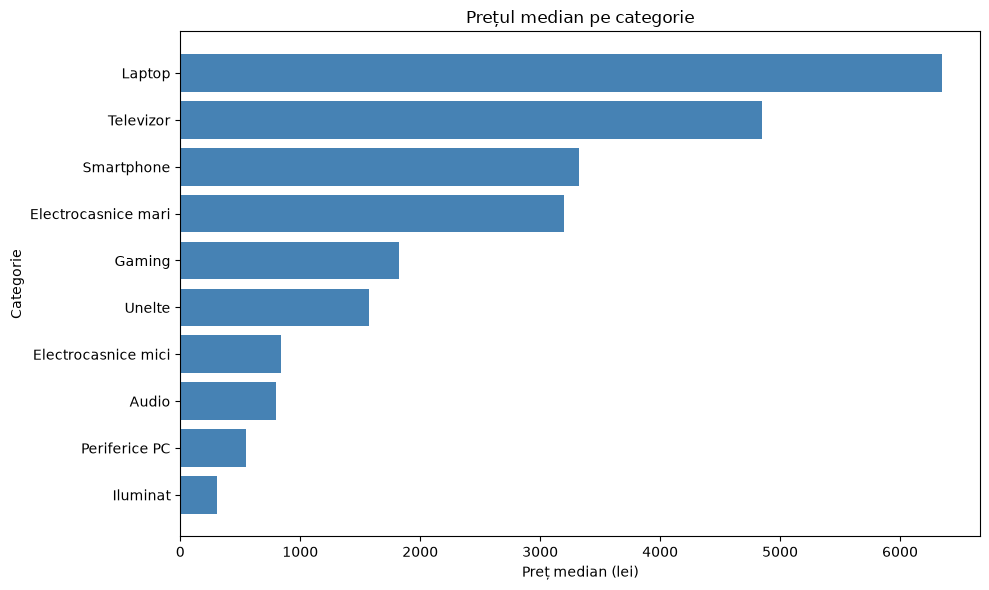

In [17]:
median_prices = (
    df_clean.groupby("Categorie")["Preț (lei)"]
    .median()
    .sort_values()
)

plt.figure(figsize=(10, 6))
plt.barh(median_prices.index, median_prices.values, color="steelblue")
plt.title("Prețul median pe categorie")
plt.xlabel("Preț median (lei)")
plt.ylabel("Categorie")
plt.tight_layout()
plt.show()

Graficul confirmă că Laptop are cel mai mare preț median, iar Iluminat cel mai mic. Barele compară medianele prețurilor din catalog; ele nu reprezintă vânzări sau cerere.

In [18]:
n_total = len(df_clean)
n_review = (df_clean["Status date"] == "Necesită verificare").sum()
review_pct = n_review / n_total * 100

category_medians = df_clean.groupby("Categorie")["Preț (lei)"].median()
highest_category = category_medians.idxmax()
lowest_category = category_medians.idxmin()

print(f"Produse analizate: {n_total}")
print(f"Produse marcate pentru verificare: {n_review} ({review_pct:.1f}%)")
print(
    f"Mediana cea mai mare: {highest_category} "
    f"({category_medians.max():,.0f} lei)"
)
print(
    f"Mediana cea mai mică: {lowest_category} "
    f"({category_medians.min():,.1f} lei)"
)

Produse analizate: 1000
Produse marcate pentru verificare: 59 (5.9%)
Mediana cea mai mare: Laptop (6,349 lei)
Mediana cea mai mică: Iluminat (306.5 lei)


## Concluzii

Analiza a acoperit 1.000 de produse. Nu am găsit valori lipsă, ID-uri sau coduri EAN duplicate, prețuri zero ori negative sau coduri EAN simulate cu cifră de control invalidă. Totuși, 59 de produse (5,9%) sunt marcate în fișier pentru verificare, cel mai frecvent pentru descrieri incomplete.

Prețul median este cel mai mare la Laptop (6.349 lei) și cel mai mic la Iluminat (306,5 lei). Regula IQR nu a semnalat valori atipice în nicio categorie.

Catalogul și prețurile sunt fictive. Rezultatele descriu acest set de date și nu pot fi folosite pentru concluzii despre piață, cerere sau vânzări.

## Cum am folosit AI-ul și am verificat rezultatele

Am folosit un asistent AI pentru a structura întrebările de analiză, a explica regula IQR și a propune cod Python cu pandas. Am rulat codul în Jupyter, iar valorile din concluzii provin din rezultatele afișate de notebook.

Am verificat rezultatele prin comparații între tabele și grafice și prin controale asupra valorilor lipsă, identificatorilor duplicați, prețurilor, monedelor și cifrelor de control EAN. Marcajele din catalog și codurile EAN sunt simulate; analiza nu confirmă informații despre produse reale.

AI-ul a ajutat la analiză, dar interpretarea rămâne limitată la setul de date disponibil. Catalogul nu conține vânzări sau date de piață.